# Bank marketing — Figure A1

UCI 222 bank marketing (45,211 rows), binning **age** into **k = 10** bins, target `y` (subscribed).
For six binnings it shows each bin's test misclassification, averaged over the paper's **9 seeds** with a
random forest. The worst bin (what MRE reports) is drawn in orange.

- **Fair Bin**: `fairbin.fair_bin`, chosen separately for each seed from that seed's training rows (70%).
  Its bin ranges can shift by a year or two across seeds; those are marked ≈.
- **Baselines**: from `baselines.py`, built the way the published A1 built them (`collect.baseline_bins`),
  that is from the **whole column, test rows included**. Set `BASELINE_ROWS = "train"` to fit them on
  each seed's training rows instead.

Takes a few minutes, mostly the 54 random-forest fits in `metrics.evaluate`. Writes `figures/A1_bank_mre_by_binning_vertical.png`.

In [1]:
import sys
from pathlib import Path

import numpy as np
from IPython.display import Image, display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import baselines, datasets, fairbin, figures, metrics

SEEDS = [92, 50, 61, 19, 11, 8, 2, 51, 70]  # the paper's nine eval seeds
K = 10
INCREMENT = 0.001                           # outer-edge padding the baselines used
NAME = "uci222_bank"
BASELINE_ROWS = "all"                       # "all": as the published A1; "train": each seed's training rows

In [2]:
data, spec, n_classes = datasets.load(NAME)
col, target = spec.bin_col, spec.target
x = data[col].to_numpy(float)
print(f"{len(data)} rows; binning {col!r} ({data[col].nunique()} distinct values); target {target!r}")

45211 rows; binning 'age' (77 distinct values); target 'y'


## Baseline bins
The baseline functions, called as `collect.baseline_bins` / `strategies.make_bins` called them.

In [3]:
def baseline_bins(s, d):
    """(binned column of `data`, bounds) for baseline s, cuts fitted on the rows of d."""
    c = d[col]
    if s == "equal_freq":
        keys, cnt = np.unique(c.to_numpy(float), return_counts=True)
        bounds = baselines.balanced_bins(keys, cnt, K)
        return fairbin.apply_bins(data[col], bounds).to_numpy(float), bounds
    if s == "equal_width":
        _, bounds, _ = baselines.gen_equal_bin(c, K, INCREMENT)
    elif s == "kmeans":
        _, bounds, _ = baselines.gen_kmeans_bin(c, K, INCREMENT)
    elif s == "jenks":
        _, bounds = baselines.gen_jenks_bin(c, K, INCREMENT)
    elif s == "entropy":
        _, bounds = baselines.gen_entropy_bin_stop(c, d[target], K, INCREMENT)
    bounds = [float(b) for b in bounds]
    return fairbin.apply_bins(data[col], bounds, right=True).to_numpy(float), bounds  # (a, b], as pd.cut

BASELINES = ["equal_width", "kmeans", "jenks", "entropy", "equal_freq"]
fixed = {s: baseline_bins(s, data) for s in BASELINES} if BASELINE_ROWS == "all" else {}
for s, (_, bounds) in fixed.items():
    print(f"{s:12s} {np.round(bounds, 2).tolist()}")

equal_width  [18.0, 25.7, 33.4, 41.1, 48.8, 56.5, 64.2, 71.9, 79.6, 87.3, 95.0]
kmeans       [18.0, 28.81, 34.72, 41.31, 48.15, 54.44, 61.03, 68.16, 75.36, 83.15, 95.0]
jenks        [18.0, 28.0, 32.0, 36.0, 40.0, 45.0, 50.0, 55.0, 63.0, 73.0, 95.0]
entropy      [18.0, 18.5, 19.5, 20.5, 21.5, 22.5, 24.5, 25.5, 29.5, 60.5, 95.0]
equal_freq   [18.0, 29.0, 32.0, 34.0, 36.0, 39.0, 42.0, 46.0, 51.0, 56.0, 95.0]


## Fit and score, per seed
For every seed: choose Fair Bin's cuts from the training rows (70%), then score each binning with `metrics.evaluate` (random forest on the binned training rows, misclassification per bin on the test rows).

In [4]:
rows = []
for seed in SEEDS:
    train = data.loc[metrics.split(data, target, seed)[0].index]
    binnings = dict(fixed) if fixed else {s: baseline_bins(s, train) for s in BASELINES}
    cuts = fairbin.fair_bin(train, target, col, K, seed)
    binnings["fairbin"] = (fairbin.apply_bins(data[col], cuts).to_numpy(float), cuts)
    for s, (binned, bounds) in binnings.items():
        bidx, _ = metrics.bin_layout(binned, bounds)
        ev = metrics.evaluate(data, col, target, binned, bidx, len(bounds) - 1, "rf", seed, n_classes == 2)
        rows += figures.bin_rows(s, seed, x, bounds, bidx, ev)
    print(f"seed {seed}: Fair Bin cuts {cuts}", flush=True)

B, G = figures.bin_table(rows, NAME)

seed 92: Fair Bin cuts [18.0, 37.0, 38.0, 40.0, 41.0, 42.0, 43.0, 44.0, 45.0, 47.0, 95.0]
seed 50: Fair Bin cuts [18.0, 37.0, 38.0, 39.0, 41.0, 42.0, 43.0, 44.0, 45.0, 46.0, 95.0]
seed 61: Fair Bin cuts [18.0, 37.0, 39.0, 40.0, 41.0, 42.0, 43.0, 44.0, 45.0, 46.0, 95.0]
seed 19: Fair Bin cuts [18.0, 36.0, 38.0, 40.0, 41.0, 42.0, 43.0, 44.0, 45.0, 46.0, 93.0]
seed 11: Fair Bin cuts [18.0, 35.0, 38.0, 40.0, 41.0, 42.0, 43.0, 44.0, 45.0, 46.0, 95.0]
seed 8: Fair Bin cuts [18.0, 37.0, 38.0, 39.0, 40.0, 41.0, 42.0, 44.0, 45.0, 46.0, 94.0]
seed 2: Fair Bin cuts [18.0, 37.0, 39.0, 40.0, 41.0, 43.0, 44.0, 45.0, 46.0, 48.0, 95.0]
seed 51: Fair Bin cuts [18.0, 36.0, 38.0, 40.0, 41.0, 42.0, 43.0, 45.0, 46.0, 48.0, 95.0]
seed 70: Fair Bin cuts [18.0, 36.0, 38.0, 39.0, 40.0, 41.0, 42.0, 43.0, 45.0, 47.0, 95.0]


## MRE per binning
`seed_mre` = `metrics.evaluate`'s MRE (each seed's worst bin), averaged over seeds: what the experiment tables report. `mre` = the worst bin of the seed-averaged errors: the orange bar.

In [5]:
worst = B.loc[B.groupby("strategy").err.idxmax(), ["strategy", "label", "err", "n_test", "seed_mre"]]
worst = worst.rename(columns={"label": "worst bin", "err": "mre"}).set_index("strategy").loc[figures.PANELS]
worst.join(G.set_index("strategy").err.rename("overall_err")).round(3)

,worst bin,mre,n_test,seed_mre,overall_err
strategy,,,,,
equal_width,72–79,0.359,91.556,0.419,0.094
kmeans,76–83,0.357,68.889,0.397,0.095
jenks,74–95,0.330,105.667,0.347,0.095
entropy,18,0.735,3.556,0.735,0.094
equal_freq,56–95,0.150,1485.889,0.151,0.095
fairbin,18–36,0.104,5288.889,0.106,0.095


## Figure A1

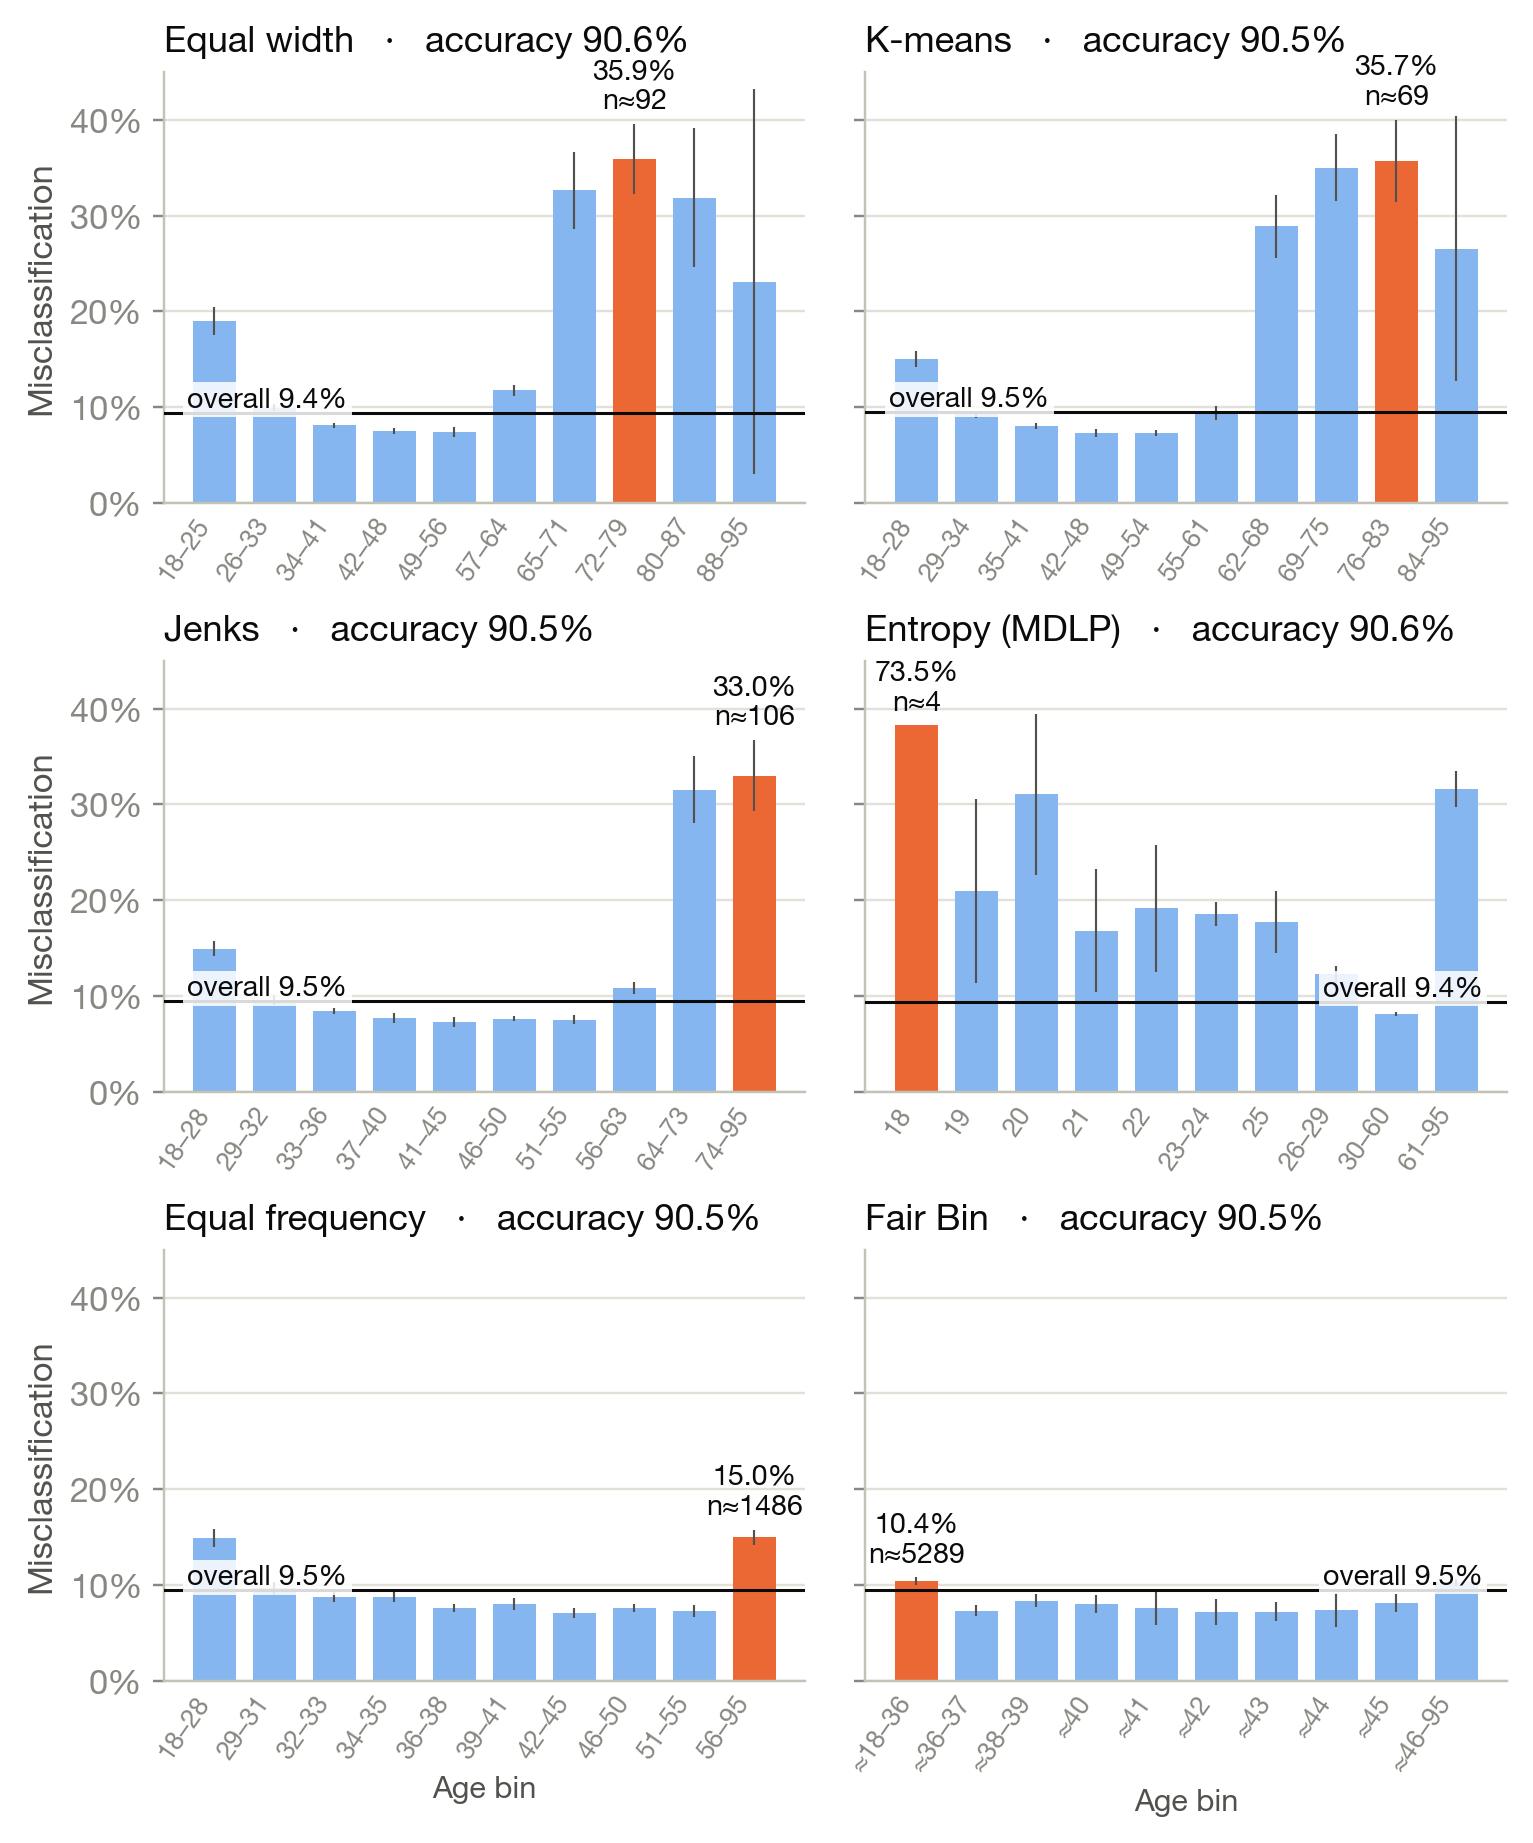

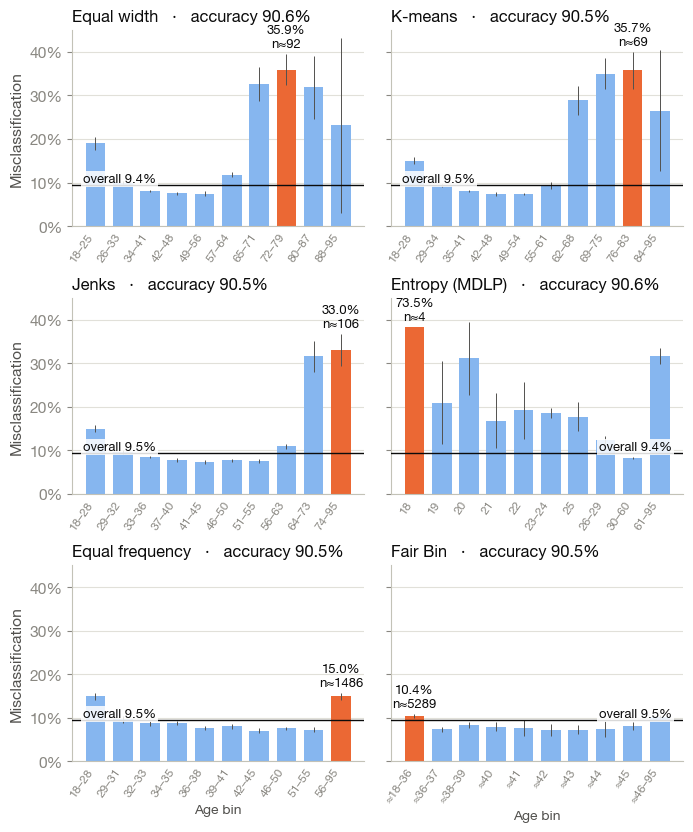

In [6]:
fig = figures.binning_panels(B, G, NAME, "err", "A1", "", "", strategies=figures.PANELS, min_n=30, grid=(3, 2),
                             bare=True, rate_label="Misclassification", ytop=0.45, solid=True, scale=1.25)
out = ROOT / "figures" / "A1_bank_mre_by_binning_vertical.png"
out.parent.mkdir(exist_ok=True)
fig.savefig(out, bbox_inches="tight", pad_inches=0.12, dpi=220)
display(Image(str(out)))